In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.anova import anova_lm


In [4]:
peng = pd.read_csv('../../data/penguins.csv')
bike = pd.read_csv('../../data/bike-sharing-daily.csv')
print(peng.head())
print(bike.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   

### Part 1

#### 1)
I would not change my selection from model 2. It had the highest Adjusted $R^2$ and avoids the probable multicollinearity between bill depth and bill length (there is likely a strong positive correlation between the two)

#### 2a)

In [13]:
corr_matrix = bike[['temp', 'hum', 'windspeed']].corr()
corr_matrix

,temp,hum,windspeed
temp,1.000000,0.126963,-0.157944
hum,0.126963,1.000000,-0.248489
windspeed,-0.157944,-0.248489,1.000000


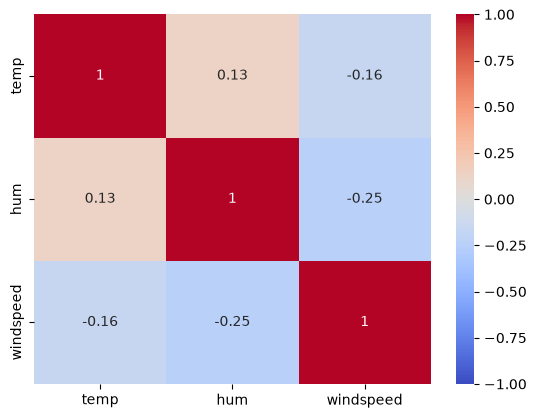

In [16]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

I've imported sm the exact same as we did in class and ran ?sm.heatmap() and it doesn't exist, so instead I used seaborns heatmap()

#### 2b)

In [ ]:
model = smf.ols('cnt ~ temp + hum + windspeed', data = bike).fit()
predictors = ['temp', 'hum', 'windspeed']
#from class
def vif_table(df, cols):
    X = sm.add_constant(df[cols])
    return pd.DataFrame({
        "variable": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).round(2)
vif_table(bike, predictors)

,variable,VIF
0,temp,1.03
1,hum,1.07
2,windspeed,1.08


The VIF is very low for all 3 predictors, so there isn't collinearity between any of them. I would think that temperature and humidity would be a little bit correlated since it's more humid in the summer than winter, but that doesn't appear to be the case. 

#### 2c) 

In [28]:
mod1 = smf.ols('cnt ~ temp', data=bike).fit()
mod2 = smf.ols('cnt ~ temp + hum', data=bike).fit()
mod3 = smf.ols('cnt ~ temp + hum + windspeed', data=bike).fit()

anova_results = anova_lm(mod1, mod2, mod3)
print(anova_results)

   df_resid           ssr  df_diff       ss_diff          F        Pr(>F)
0     729.0  1.660847e+09      0.0           NaN        NaN           NaN
1     728.0  1.570304e+09      1.0  9.054330e+07  44.569779  4.869005e-11
2     727.0  1.476897e+09      1.0  9.340630e+07  45.979085  2.475445e-11


I would choose model 3. It adds more predictive power by adding additional predictor(s) that are not strongly correlated to the existing predictor(s) as shown by the heat map above. The tiny p-values in the anova test means that the model improvements from adding predictors were significant. 

### Part 2

#### 1) 

In [36]:
newPeng = peng.dropna(subset='sex')

model = smf.ols('body_mass_g ~ flipper_length_mm + bill_depth_mm + ' \
'bill_length_mm', data=newPeng).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.764
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     354.9
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          9.26e-103
Time:                        13:06:20   Log-Likelihood:                -2459.8
No. Observations:                 333   AIC:                             4928.
Df Residuals:                     329   BIC:                             4943.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -6445.4760    566.13

The adjusted $R^2$ is the same, which I think is due to the fact that I noticed missing values and dropped them when I loaded the dataset last week. The coefficients are the same as well. 

#### 2) 

In [45]:
mod_peng_flip = smf.ols('body_mass_g ~ flipper_length_mm', data=newPeng).fit()
mod_peng_add = smf.ols('body_mass_g ~ flipper_length_mm + C(sex)', data=newPeng).fit()
mod_peng_int = smf.ols('body_mass_g ~ flipper_length_mm * C(sex)', data=newPeng).fit()

print(mod_peng_add.summary())
print('\n', anova_lm(mod_peng_flip, mod_peng_add, mod_peng_int))

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.805
Method:                 Least Squares   F-statistic:                     684.8
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          3.53e-118
Time:                        13:22:44   Log-Likelihood:                -2427.2
No. Observations:                 333   AIC:                             4860.
Df Residuals:                     330   BIC:                             4872.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5410.3002    285.79

Text(0, 0.5, 'Body Mass in grams')

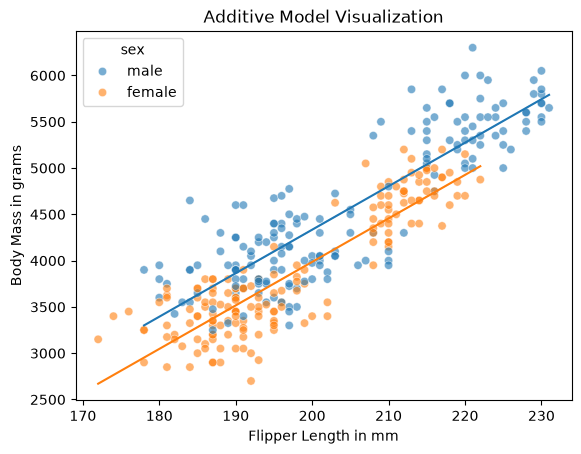

In [50]:
newPeng['predicted_mass_add'] = mod_peng_add.fittedvalues # for the plot here


sns.scatterplot(x='flipper_length_mm', y='body_mass_g', hue='sex', 
    data=newPeng, alpha=0.6)
sns.lineplot(x='flipper_length_mm', y='predicted_mass_add', hue='sex', 
    data=newPeng, legend=False)

plt.title("Additive Model Visualization")
plt.xlabel("Flipper Length in mm")
plt.ylabel("Body Mass in grams")

- a) I'd choose the additive model because adding the interaction term doesn't make the model significantly better with a p-value of 0.92
- b) The average male penguin is expected to be 347.85 grams heavier than the average female penguin with the same flipper length in mm. This shows a linear shift in the regression line, meaning that for any flipper length, the expected difference between male and female penguin is a constant. 
- c) The visualization shows the difference in estimated weight by flipper length for both male and female penguins. It effectively demonstrates my point in part b how the additive model doesn't change the slope of the regression line, rather just shifting it. 

#### 3) 

In [58]:
mod_cat_add = smf.ols('body_mass_g ~ C(sex) + C(species)', data=newPeng).fit()
mod_cat_int = smf.ols('body_mass_g ~ C(sex) * C(species)', data=newPeng).fit()
print(anova_lm(mod_cat_add, mod_cat_int))

   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     329.0  3.297919e+07      0.0           NaN       NaN       NaN
1     327.0  3.130263e+07      2.0  1.676557e+06  8.756997  0.000197


In [55]:
print(mod_cat_int.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.855
Model:                            OLS   Adj. R-squared:                  0.852
Method:                 Least Squares   F-statistic:                     384.3
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          1.54e-134
Time:                        13:43:39   Log-Likelihood:                -2379.1
No. Observations:                 333   AIC:                             4770.
Df Residuals:                     327   BIC:                             4793.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

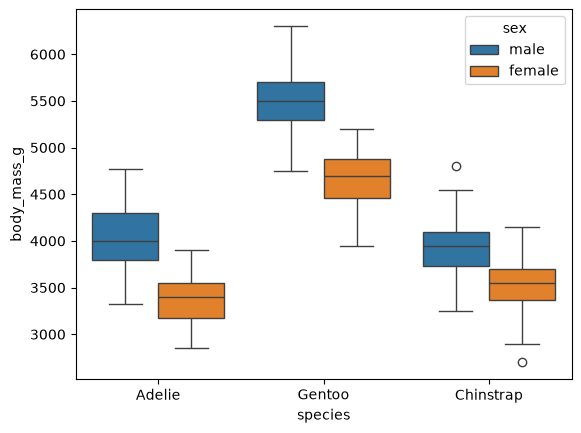

In [59]:
sns.boxplot(x='species', y='body_mass_g', hue='sex', data=newPeng)
plt.show()

- a) According to the anova test, the interactive model is much better than the additive one when controlling for species.
- b) Intercept: The average female adelie penguin is 3369 grams;   C(sex)[T.male]: The average difference in mass for a male adelie penguin is 675 grams heavier than a female adelie penguin;   C(species)[T.Chinstrap]: The average difference in mass between a female chinstrap and female adelie penguin. The average female chinstrap is expected to be 158 grams larger;   C(species)[T.Gentoo]: The average difference in mass between a female gentoo and female adelie penguin. The average female gentoo is expected to be 1311 grams larger;   C(sex)[T.male]:C(species)[T.Chinstrap]: The interaction adjustment -263 shows that the average male chinstrap is 263 grams lighter than the average male adelie;   C(sex)[T.male]:C(species)[T.Gentoo]: The interaction adjustment 130 shows that the average male gentoo is 130 grams heavier than the average male adelie
- c) The boxplot sort of shows the difference (although not exactly) in mass between sex for each species. For example the gentoos have the largest gap in mass by sex while the male and female chinstraps are much similar in size. 

#### 4) 

In [60]:
modelb = smf.ols('casual ~ temp + C(workingday) + hum + windspeed', data=bike).fit()
modelb2 = smf.ols('casual ~ temp + C(workingday) + hum + windspeed + temp*workingday', data=bike).fit()

In [61]:
print(modelb.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     307.9
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          9.84e-155
Time:                        16:52:31   Log-Likelihood:                -5448.9
No. Observations:                 731   AIC:                         1.091e+04
Df Residuals:                     726   BIC:                         1.093e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           1063.5527    101

In [62]:
print(modelb2.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.677
Method:                 Least Squares   F-statistic:                     307.4
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          2.25e-176
Time:                        16:52:45   Log-Likelihood:                -5395.6
No. Observations:                 731   AIC:                         1.080e+04
Df Residuals:                     725   BIC:                         1.083e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            492.5703    108

In [63]:
print(anova_lm(modelb, modelb2))

   df_resid           ssr  df_diff       ss_diff           F        Pr(>F)
0     726.0  1.276423e+08      0.0           NaN         NaN           NaN
1     725.0  1.103186e+08      1.0  1.732378e+07  113.849712  8.681452e-25


#### Answer for part a

I would choose the second model since the interaction term is highly significant and has a slightly better adjusted $R^2$, and running an anova test on the two models favors the second model as well. 

In [64]:
modelb3 = smf.ols('registered ~ temp + C(workingday) + hum + windspeed', data=bike).fit()
modelb4 = smf.ols('registered ~ temp + C(workingday) + hum + windspeed + temp*workingday', data=bike).fit()

In [66]:
print(modelb3.summary())

                            OLS Regression Results                            
Dep. Variable:             registered   R-squared:                       0.426
Model:                            OLS   Adj. R-squared:                  0.422
Method:                 Least Squares   F-statistic:                     134.5
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           5.97e-86
Time:                        16:59:53   Log-Likelihood:                -6208.8
No. Observations:                 731   AIC:                         1.243e+04
Df Residuals:                     726   BIC:                         1.245e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           2945.8161    286

In [67]:
print(modelb4.summary())

                            OLS Regression Results                            
Dep. Variable:             registered   R-squared:                       0.428
Model:                            OLS   Adj. R-squared:                  0.424
Method:                 Least Squares   F-statistic:                     108.4
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           1.89e-85
Time:                        17:00:00   Log-Likelihood:                -6207.4
No. Observations:                 731   AIC:                         1.243e+04
Df Residuals:                     725   BIC:                         1.245e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           3215.1761    329

In [68]:
print(anova_lm(modelb3, modelb4))

   df_resid           ssr  df_diff       ss_diff         F   Pr(>F)
0     726.0  1.020706e+09      0.0           NaN       NaN      NaN
1     725.0  1.016851e+09      1.0  3.855347e+06  2.748806  0.09776


#### Answer for b: 

For predicting registered instead of casual using the same predictors, I would choose the first model without the interaction term. The interaction term's coefficient is not significant and neither is the anova test, so I don't think it's worth it to add another regressor to the model. 

#### C: 

The significance of the interaction between temperature and working day for casual riders infer that if the weather is hotter, casual riders are more likely to rent a bike. People who are registered users likely use the bikes for more transportation than leisure, which is why there isn't a significant interaction between temp and workingday there. 

#### D:

Keeping the models separate instead of overwriting them allows you to keep the model stored in case you want to revisit it in the future. 

### Part 3: 

#### 1) 

In [80]:
peng_342 = peng.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']).copy()
mod_342 = smf.ols('body_mass_g ~ flipper_length_mm + bill_depth_mm + bill_length_mm', data=peng_342).fit() # new model cus I believe I overwrote it... ironic timing
infl = OLSInfluence(mod_342)

diag_df = pd.DataFrame({'actual': peng_342['body_mass_g'], 'predicted': mod_342.fittedvalues,
    'stud_resid': infl.resid_studentized_internal, 'leverage': infl.hat_matrix_diag,
    'cooks_d': infl.cooks_distance[0]})

missing_sex_indices = peng_342[peng_342['sex'].isna()].index
diag_df['missing_sex'] = diag_df.index.isin(missing_sex_indices)

In [81]:
# leverage cutoff = 0.0246   Cook's D cutoff = 0.0055

n = len(peng_342)
p = len(mod_342.params)
leverage_cutoff = 2 * p / n
cooks_cutoff = 4 / n

print(f"Leverage Cutoff: {leverage_cutoff:.4f}")
print(f"Cook's D Cutoff: {cooks_cutoff:.4f}")

# Check the 9 missing-sex penguins against cutoffs
print(diag_df[diag_df['missing_sex']])

Leverage Cutoff: 0.0234
Cook's D Cutoff: 0.0117
     actual    predicted  stud_resid  leverage   cooks_d  missing_sex
8    3475.0  3782.009706   -0.786580  0.015675  0.002463         True
9    4250.0  3706.184442    1.389313  0.010026  0.004887         True
10   3300.0  3425.474357   -0.320310  0.008505  0.000220         True
11   3700.0  3127.868934    1.463271  0.012216  0.006620         True
47   2975.0  3108.430419   -0.340906  0.010170  0.000299         True
178  4100.0  4905.296510   -2.057524  0.010211  0.010919         True
218  4650.0  4813.838115   -0.418281  0.008677  0.000383         True
256  4725.0  4906.924841   -0.465126  0.011531  0.000631         True
268  4875.0  4983.635078   -0.277385  0.008949  0.000174         True


None of the dropped penguins are past the leverage or cook's cutoffs, so removing these points didn't skew the model too drastically and that the values dropped were just sort of average/random.

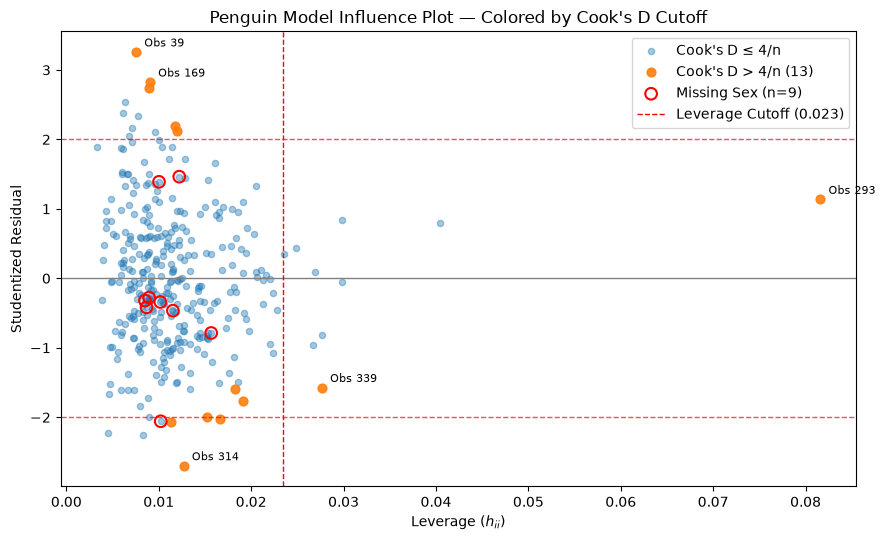

In [90]:
# ai helped with fitting the code used for the in class visual to this data, the plot looks like the one in class 

infl = diag_df['cooks_d'] > cooks_cutoff

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    diag_df.loc[~infl, 'leverage'], 
    diag_df.loc[~infl, 'stud_resid'], 
    s=20, alpha=0.4, color="tab:blue", label=f"Cook's D ≤ 4/n"
)

ax.scatter(
    diag_df.loc[infl, 'leverage'], 
    diag_df.loc[infl, 'stud_resid'], 
    s=40, alpha=0.9, color="tab:orange", label=f"Cook's D > 4/n ({infl.sum()})"
)

missing_sex_mask = diag_df['missing_sex']
ax.scatter(
    diag_df.loc[missing_sex_mask, 'leverage'], 
    diag_df.loc[missing_sex_mask, 'stud_resid'],
    s=70, facecolors='none', edgecolors='red', linewidth=1.5, label='Missing Sex (n=9)'
)

ax.axhline(0, color="gray", lw=1)
for y in (-2, 2): 
    ax.axhline(y, color="red", ls="--", lw=1, alpha=0.7)
ax.axvline(leverage_cutoff, color="red", ls="--", lw=1, label=f"Leverage Cutoff ({leverage_cutoff:.3f})")

ax.set(
    xlabel="Leverage ($h_{ii}$)", 
    ylabel="Studentized Residual",
    title="Penguin Model Influence Plot — Colored by Cook's D Cutoff"
)
ax.legend(loc='upper right')

for idx, r in diag_df.nlargest(5, "cooks_d").iterrows():
    ax.annotate(
        f"Obs {idx}", 
        (r.leverage, r.stud_resid),
        fontsize=8, 
        xytext=(6, 4), 
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

### 2) 

In [ ]:
bike_no_sandy = bike[bike['dteday'] != '2012-10-29']
bike_no_march = bike[bike['dteday'] != '2012-03-17']

model_no_sandy = smf.ols('cnt ~ temp + hum + windspeed', data=bike_no_sandy).fit()
print("Without Sandy:\n", model_no_sandy.summary())

Without Sandy:
                             OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.457
Method:                 Least Squares   F-statistic:                     205.6
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           1.70e-96
Time:                        17:44:07   Log-Likelihood:                -6334.1
No. Observations:                 730   AIC:                         1.268e+04
Df Residuals:                     726   BIC:                         1.269e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4027.4266    338.847    

In [93]:
mod_no_march = smf.ols('cnt ~ temp + hum + windspeed', data=bike_no_march).fit()
print("\nWithout March 17:\n", mod_no_march.summary())


Without March 17:
                             OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.463
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     208.2
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           1.95e-97
Time:                        17:44:23   Log-Likelihood:                -6333.1
No. Observations:                 730   AIC:                         1.267e+04
Df Residuals:                     726   BIC:                         1.269e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4082.5122    336.903

I think removing the hurrican sandy datapoint but not the march 17 one would be reasonable. Sandy was an extremely rare, unpredictable event that obviously had a huge effect on how people rent bikes whereas St. Patricks day, while being influential on the model, occurs every year and would be better off left in the dataset. 

### Part 5: 

I found the readings on transformations fairly interesting. It makes a lot of sense how they boost model accuracy, especially data that's exponential like the planets dataset last lab. I was a little surprised to learn that transformations don't affect decision trees, but after thinking about it it makes sense that the boundary would just trnasform with the data. Overall this is a tool I'm not all too familiar with, but it's definitely something I want to explore using more in my models. 

Can we go over the math of why log transformations are interpreted as percentages in class?